# Scenarios, weights and the non-linearity of ECL

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 and 02 of this topic
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- write the point-in-time PD as a function of a systematic factor and convert between a default rate and the factor it implies;
- show with numbers why the probability-weighted PD is not the PD of the average scenario, and why a "base" scenario at $z = 0$ is the median and not the mean;
- verify the Gauss-Hermite integration over the factor and say how many nodes the engine's identity needs;
- weight the ECL of three scenarios, reproduce the committed stage totals and read the weight sensitivity as an exact linear derivative;
- tell the two non-linearity indexes apart (the PD level and the ECL level) and measure what re-staging adds when the weights move.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data is case C06 at the reporting date 2008-12-31 (SBA 7(a) loans, U.S. Government Works, licence class `mirror-allowed`; the macroeconomic scenarios are shapes of the Federal Reserve's 2026 stress-test paths, mirror-allowed). One file is read, `data/derived/C06/rd-2008-12.json`:

- `outputs.scenarios`: three scenarios with their weight and their mean systematic factor $z$;
- `outputs.ecl_by_scenario`: the ECL of each scenario and stage, with the stages fixed at the weighted allocation;
- `outputs.weight_grid`: fifteen weight vectors on a grid of step 0.25, with the ECL **with the staging frozen** and the ECL **with the staging recomputed** at those weights;
- `outputs.non_linearity`: the PD-level and the ECL-level comparison of the weighted measure with the mean path, and the curve of the conditional PD against $z$.

The next cell loads the artifact and prints the scenarios, the weights and the engine versions.

In [2]:
# Load the reporting-date artifact and list its scenarios with their weights and factors
from riskvalidation.provisions import ecl as ecl_engine, term_structure as tsm
from riskvalidation.validation import ifrs9

LANG = "en"
ROOT = Path("../../..").resolve()
case = json.loads((ROOT / "data" / "derived" / "C06" / "rd-2008-12.json").read_text(encoding="utf-8"))
out = case["outputs"]

for s in out["scenarios"]:
    print(f"{s['id']:18s} weight: {s['weight']:.2f} | mean factor z: {s['z_mean']:.4f} | {s['label'][LANG]}")
print("engine that baked the artifact:", case["provenance"]["riskvalidation_version"], "| installed engine:", md.version("riskvalidation"))
print("findings of the artifact:", [f["id"] for f in case["findings"]])

baseline           weight: 0.60 | mean factor z: -1.4801 | Baseline (Fed 2026 shape)
adverse            weight: 0.30 | mean factor z: -1.3735 | Adverse (midpoint of the Fed shapes, Contraste's own)
severely-adverse   weight: 0.10 | mean factor z: -1.3478 | Severely adverse (Fed 2026 shape)
engine that baked the artifact: 0.5.0 | installed engine: 0.8.1
findings of the artifact: ['F-SICR-amber', 'F-MIGRATION-red', 'F-SCENARIO-ORDER', 'F-NO-DELINQUENCY', 'F-LGD-PROXY', 'F-EAD-MODEL', 'F-PREPAYMENT', 'F-SHORT-LIFE']


## Method

IFRS 9 asks for an unbiased, probability-weighted amount (5.5.17(a)), built with more than one scenario when the loss is not linear in the macroeconomic path (B5.5.41 and B5.5.42; GPPC 2016, section 2.8.1.2). Three results carry this notebook.

**1. The conditional PD.** In the one-factor model of the IRB formula (BCBS 2005, section 4.2; Gordy 2003), an obligor defaults when its asset return, $\sqrt{\rho}\,Z + \sqrt{1-\rho}\,\varepsilon$, falls below $\Phi^{-1}(PD^{\mathrm{TTC}})$, with $Z$ and $\varepsilon$ standard normal and independent. The PD given the systematic factor $z$ is

$$PD^{\mathrm{PIT}}(z) = \Phi\!\left(\frac{\Phi^{-1}(PD^{\mathrm{TTC}}) - \sqrt{\rho}\,z}{\sqrt{1-\rho}}\right), \qquad \mathbb{E}_Z\bigl[PD^{\mathrm{PIT}}(Z)\bigr] = PD^{\mathrm{TTC}}$$

and its inverse gives the factor implied by an observed default rate $DR$: $z = \bigl(\Phi^{-1}(PD^{\mathrm{TTC}}) - \sqrt{1-\rho}\,\Phi^{-1}(DR)\bigr)/\sqrt{\rho}$. A negative $z$ is a bad year.

**2. The weighted measure and its non-linearity.**

$$\mathrm{ECL} = \sum_s w_s\,\mathrm{ECL}_s, \quad w_s \ge 0, \;\sum_s w_s = 1, \qquad \mathrm{NL} = \frac{\mathrm{ECL}_{\mathrm{weighted}}}{\mathrm{ECL}(\text{mean path})} - 1$$

Because $PD^{\mathrm{PIT}}$ is convex in $z$ over the usual range, Jensen's inequality gives $\mathbb{E}[PD(Z)] \ge PD(\mathbb{E}[Z])$: the weighted measure is at least the measure at the average scenario. The ECB (2024) criticises macro overlays built on the average path because they ignore this non-linearity and underestimate the mean impact.

**3. The weight sensitivity.** The ECL is linear in the weights, so moving weight from a reference scenario to $s$ changes it by $\partial\,\mathrm{ECL}/\partial w_s = \mathrm{ECL}_s - \mathrm{ECL}_{\mathrm{ref}}$ (BCBS d350, paragraph 36(a)). Staging is not linear in the weights when the SICR test uses weighted PDs (GPPC 2016, 2.7.2.10), so the engine's committed grid reports both versions: staging frozen (exactly linear) and staging recomputed.

The 100 per cent single-scenario ECLs are sensitivities, never the IFRS 9 measure.

### Step 1: the conditional PD curve of the book, and its inverse

The artifact gives the book's $PD^{\mathrm{TTC}}$ and $\rho$ (`non_linearity.parameters`) and the committed curve of the conditional PD at $z = -3, \dots, 3$. The cell evaluates `ttc_to_pit` at the same factors and compares. It then applies `implied_z` to the default rates the curve gives and checks that the factors come back.

In [3]:
# Evaluate the conditional PD at the committed factors and recover the factors with the inverse
nl = out["non_linearity"]
pd_ttc, rho = nl["parameters"]["pd_ttc"], nl["parameters"]["rho"]
z_grid = np.array([p["z"] for p in nl["z_curve"]])
committed_curve = np.array([p["pd_pit"] for p in nl["z_curve"]])
curve = tsm.ttc_to_pit(np.full(z_grid.size, pd_ttc), rho, z_grid)
print("PD_TTC:", round(pd_ttc, 6), "| rho:", rho)
print("conditional PD equal to the committed curve within 1e-9:", bool(np.allclose(curve, committed_curve, atol=1e-9, rtol=0)))
for z_, p_ in zip(z_grid, curve):
    print("z =", f"{z_:+.0f}", "| PD(z):", round(float(p_), 6))
back = tsm.implied_z(curve, pd_ttc, rho)
print("factors recovered by the inverse:", bool(np.allclose(back, z_grid, atol=1e-9, rtol=0)))

PD_TTC: 0.016389 | rho: 0.12
conditional PD equal to the committed curve within 1e-9: True
z = -3 | PD(z): 0.121428
z = -2 | PD(z): 0.062128
z = -1 | PD(z): 0.028298
z = +0 | PD(z): 0.011432
z = +1 | PD(z): 0.004085
z = +2 | PD(z): 0.001288
z = +3 | PD(z): 0.000358
factors recovered by the inverse: True


### Step 2: a worked example of the non-linearity, and the median trap

The engine's reference example comes from the dossier's illustration: $PD^{\mathrm{TTC}} = 2\%$, $\rho = 0.12$, three scenarios at $z = +1$ (upside, weight 0.25), $z = 0$ (base, 0.50) and $z = -2$ (downside, 0.25). These are **inputs of the lesson**, chosen for the example, not data of C06. The cell computes the conditional PD of each scenario with `ttc_to_pit`, the weighted PD with `weighted_pit_pd`, the PD at the weighted-average factor, and the engine's own test `nonlinearity_test`, which returns the index and the Gauss-Hermite check. With a loss given default of 40% it then converts both PDs into a one-year loss rate.

In [4]:
# The reference example: three scenarios, the weighted PD, the PD at the mean factor and the engine's own test
EX_PD, EX_RHO = 0.02, 0.12  # inputs of the lesson
ex_z = np.array([1.0, 0.0, -2.0])
ex_w = np.array([0.25, 0.50, 0.25])
ex_lgd = 0.40

per_scenario = tsm.ttc_to_pit(EX_PD, EX_RHO, ex_z)
weighted = tsm.weighted_pit_pd(EX_PD, EX_RHO, ex_z, ex_w)
mean_z = float(np.sum(ex_w * ex_z))
at_mean = float(tsm.ttc_to_pit(EX_PD, EX_RHO, mean_z))
print("conditional PD by scenario (percent):", np.round(100 * per_scenario, 3))
print("weighted PD (percent):", round(100 * weighted, 3), "| weighted mean factor:", mean_z, "| PD at that factor (percent):", round(100 * at_mean, 3), "| ratio:", round(weighted / at_mean, 2))
print("loss rate, weighted and at the mean factor (percent):", round(100 * ex_lgd * weighted, 2), round(100 * ex_lgd * at_mean, 2))

test = ifrs9.nonlinearity_test(EX_PD, EX_RHO, ex_z, ex_w, model_id="lesson")
print("engine test, index:", round(test.metric, 4), "| Gauss-Hermite error within 1e-9:", test.extras["gauss_hermite_error"] <= 1e-9, "|", test.light.value)
print("PD at z = 0 (the median) and the unconditional PD (percent):", round(100 * float(per_scenario[1]), 3), round(100 * EX_PD, 3))

conditional PD by scenario (percent): [0.526 1.429 7.342]
weighted PD (percent): 2.681 | weighted mean factor: -0.25 | PD at that factor (percent): 1.8 | ratio: 1.49
loss rate, weighted and at the mean factor (percent): 1.07 0.72
engine test, index: 0.4898 | Gauss-Hermite error within 1e-9: True | green
PD at z = 0 (the median) and the unconditional PD (percent): 1.429 2.0


### Step 3: the Gauss-Hermite check

The identity $\mathbb{E}_Z[PD^{\mathrm{PIT}}(Z)] = PD^{\mathrm{TTC}}$ is the engine's cross-check of the non-linearity. `gauss_hermite_pit_pd` integrates the conditional PD over the standard normal with probabilists' Gauss-Hermite nodes. The cell raises the number of nodes and prints the error against $PD^{\mathrm{TTC}}$: with few nodes the integral is crude, and the docstring promises 1e-9 from 32 nodes.

In [5]:
# The error of the integral against PD_TTC as the number of nodes grows (floored at 1e-16, the rounding of the arithmetic)
for nodes in (2, 4, 8, 16, 32, 64):
    integral = tsm.gauss_hermite_pit_pd(EX_PD, EX_RHO, nodes)
    print("nodes", f"{nodes:3d}", "| error against PD_TTC:", f"{max(abs(integral - EX_PD), 1e-16):.0e}")
print("within 1e-9 from 32 nodes:", abs(tsm.gauss_hermite_pit_pd(EX_PD, EX_RHO, 32) - EX_PD) <= 1e-9)

nodes   2 | error against PD_TTC: 2e-04
nodes   4 | error against PD_TTC: 5e-07
nodes   8 | error against PD_TTC: 9e-12
nodes  16 | error against PD_TTC: 1e-16
nodes  32 | error against PD_TTC: 1e-16
nodes  64 | error against PD_TTC: 1e-16
within 1e-9 from 32 nodes: True


### Step 4: the same two comparisons on the committed book

Back to C06. The artifact gives the three scenario factors and weights it used. The cell recomputes the weighted PD and the PD at the weighted mean factor of the book with `weighted_pit_pd` and `ttc_to_pit` and compares them with the committed ones. It then reads the **ECL level**: the committed weighted ECL and the ECL at the mean path give the index through `non_linearity_index`. The two indexes are not the same quantity: the first is about a one-year PD of the book, the second about the whole ECL, with lifetime paths and staging.

In [6]:
# Recompute the book's weighted PD and PD at the mean factor, then the ECL-level index from the committed pair
points = nl["scenario_points"]
z_book = np.array([p["z"] for p in points])
w_book = np.array([p["weight"] for p in points])
pd_weighted = tsm.weighted_pit_pd(pd_ttc, rho, z_book, w_book)
pd_mean = float(tsm.ttc_to_pit(pd_ttc, rho, float(np.sum(w_book * z_book))))
print("weighted PD, engine and committed:", round(pd_weighted, 8), round(nl["pd_weighted"], 8))
print("PD at the mean factor, engine and committed:", round(pd_mean, 8), round(nl["pd_at_mean_z"], 8))
pd_index = ecl_engine.non_linearity_index(pd_weighted, pd_mean)
ecl_index = ecl_engine.non_linearity_index(nl["ecl_weighted"], nl["ecl_at_mean_path"])
print("PD-level index, engine and committed (the PD-level test row):", round(pd_index, 6), [round(t["metric"], 6) for t in case["tests"] if t["test_id"] == "ifrs9.nonlinearity"])
print("ECL-level index, engine and committed:", round(ecl_index, 6), round(nl["index"], 6))
print("the ECL-level index over the PD-level index:", round(ecl_index / pd_index, 1))
print("baked by engine", case["provenance"]["riskvalidation_version"], "| read with engine", md.version("riskvalidation"))

weighted PD, engine and committed: 0.04045198 0.04045198
PD at the mean factor, engine and committed: 0.04041987 0.04041987
PD-level index, engine and committed (the PD-level test row): 0.000794 [0.000794]
ECL-level index, engine and committed: 0.02121 0.02121
the ECL-level index over the PD-level index: 26.7
baked by engine 0.5.0 | read with engine 0.8.1


### Step 5: weighting the scenario ECLs and reproducing the stage totals

`ecl_by_scenario` holds the ECL of each scenario by stage, with the stages fixed. We stack the three scenarios into an array of shape (scenarios, stages) and weight it with `probability_weighted_ecl`. The result must equal the committed `stage_summary`: the allowance of the book at this date. The cell also prints the 100 per cent single-scenario ECLs (the totals of each row), which are sensitivities and not the measure.

In [7]:
# Weight the scenario ECLs by stage and compare with the committed stage totals
ids = [s["id"] for s in out["scenarios"]]
weights = np.array([s["weight"] for s in out["scenarios"]])
stages = ("stage1", "stage2", "stage3")
by = {(r["scenario_id"], r["stage"]): r["ecl"] for r in out["ecl_by_scenario"]["rows"]}
matrix = np.array([[by[(sid, st)] for st in stages] for sid in ids])
weighted_by_stage = ecl_engine.probability_weighted_ecl(matrix, weights)
committed = {r["stage"]: r["ecl"] for r in out["stage_summary"]["rows"]}
for st, value in zip(stages, weighted_by_stage):
    print(st, "| weighted, USD millions:", round(float(value) / 1e6, 3), "| committed:", round(committed[st] / 1e6, 3))
single = matrix.sum(axis=1)
for sid, value in zip(ids, single):
    print(f"{sid:18s} ECL at 100 percent of the scenario, USD millions: {value / 1e6:9.3f}")
total = float(weighted_by_stage.sum())
print("weighted total, USD millions:", round(total / 1e6, 3), "| ECL at the mean path:", round(nl["ecl_at_mean_path"] / 1e6, 3))
print("finding:", [f["title"][LANG] for f in case["findings"] if f["id"] == "F-SCENARIO-ORDER"][0])

stage1 | weighted, USD millions: 798.078 | committed: 798.078
stage2 | weighted, USD millions: 68.929 | committed: 68.929
stage3 | weighted, USD millions: 0.0 | committed: 0.0
baseline           ECL at 100 percent of the scenario, USD millions:   897.476
adverse            ECL at 100 percent of the scenario, USD millions:   825.460
severely-adverse   ECL at 100 percent of the scenario, USD millions:   808.827
weighted total, USD millions: 867.007 | ECL at the mean path: 848.999
finding: The severely adverse scenario gives a lower ECL than the baseline: the hazard's macro sensitivities have the wrong sign at this date


### Step 6: the weight sensitivity, linear when the staging is frozen

With the stages fixed the ECL is linear in the weights, so `weight_sensitivity` returns the exact change of moving weight to each scenario from a reference. The cell checks the committed grid. For each of the fifteen weight vectors it weights the single-scenario totals with `probability_weighted_ecl` and compares with the committed `ecl_frozen`: they must be equal. It then prints, for the committed grid, how much the ECL changes when the staging is recomputed at those weights and how the Stage 2 share of the gross amount moves, which is the contribution of staging that a linear sensitivity cannot see.

In [8]:
# Check the frozen-staging grid against the linear weighting and measure the staging contribution
grid = out["weight_grid"]["points"]
frozen_engine = np.array([float(ecl_engine.probability_weighted_ecl(single, np.array(p["weights"]))) for p in grid])
frozen_committed = np.array([p["ecl_frozen"] for p in grid])
recomputed = np.array([p["ecl_recomputed"] for p in grid])
print("weight vectors on the grid:", len(grid))
print("frozen ECL equals the linear weighting within 1 USD:", bool(np.allclose(frozen_engine, frozen_committed, atol=1.0, rtol=0)))
sens = ecl_engine.weight_sensitivity(single, 0)
print("change of moving all weight from the baseline to each scenario, USD millions:", np.round(sens / 1e6, 3))
difference = recomputed - frozen_committed
print("recomputed minus frozen ECL on the grid, USD millions, smallest and largest:", round(float(difference.min()) / 1e6, 3), round(float(difference.max()) / 1e6, 3))
share_frozen = {p["stage2_ratio_frozen"] for p in grid}
share_recomputed = [p["stage2_ratio_recomputed"] for p in grid]
print("Stage 2 share, frozen (one value):", sorted(round(x, 5) for x in share_frozen), "| recomputed, smallest and largest:", round(min(share_recomputed), 5), round(max(share_recomputed), 5))
for p in grid[:5]:
    print("weights", p["weights"], "| frozen:", round(p["ecl_frozen"] / 1e6, 2), "| recomputed:", round(p["ecl_recomputed"] / 1e6, 2))

weight vectors on the grid: 15
frozen ECL equals the linear weighting within 1 USD: True
change of moving all weight from the baseline to each scenario, USD millions: [  0.    -72.016 -88.65 ]
recomputed minus frozen ECL on the grid, USD millions, smallest and largest: -15.235 2.089
Stage 2 share, frozen (one value): [0.01125] | recomputed, smallest and largest: 0.00779 0.01236
weights [0.0, 0.0, 1.0] | frozen: 808.83 | recomputed: 793.72
weights [0.0, 0.25, 0.75] | frozen: 812.99 | recomputed: 797.9
weights [0.0, 0.5, 0.5] | frozen: 817.14 | recomputed: 801.98
weights [0.0, 0.75, 0.25] | frozen: 821.3 | recomputed: 806.07
weights [0.0, 1.0, 0.0] | frozen: 825.46 | recomputed: 810.75


### Step 7: the curve, the chord and the grid, drawn

The left panel draws the conditional PD of the step 2 example against the factor, its three scenario points, the PD at the weighted mean factor (the square) and the weighted PD (the dashed line): the dashed line lies above the square because the curve bends upward. On the committed book the three factors lie close together, so the same gap is small and would not show. The right panel draws, along the edge of the simplex with no weight on the adverse scenario, the ECL with the staging frozen (a straight line) and with the staging recomputed (not a straight line) against the weight of the baseline scenario.

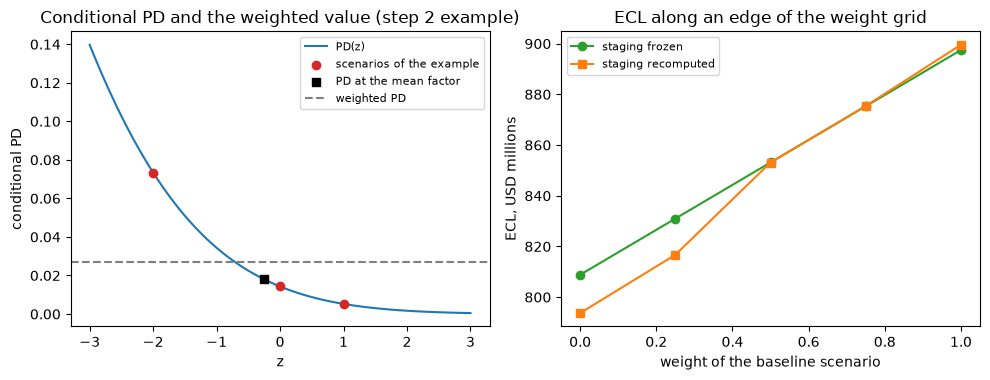

In [9]:
# Draw the example's conditional PD with its scenario points, and the frozen and recomputed ECL along an edge of the weight grid
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.9))
zz = np.linspace(-3.0, 3.0, 121)
left.plot(zz, tsm.ttc_to_pit(np.full(zz.size, EX_PD), EX_RHO, zz), color="tab:blue", label="PD(z)")
left.scatter(ex_z, per_scenario, color="tab:red", zorder=3, label="scenarios of the example")
left.scatter([mean_z], [at_mean], color="black", marker="s", zorder=3, label="PD at the mean factor")
left.axhline(weighted, color="grey", linestyle="--", label="weighted PD")
left.set_xlabel("z")
left.set_ylabel("conditional PD")
left.set_title("Conditional PD and the weighted value (step 2 example)")
left.legend(fontsize=8)

edge = sorted((p for p in grid if p["weights"][1] == 0.0), key=lambda p: p["weights"][0])
xs = [p["weights"][0] for p in edge]
right.plot(xs, [p["ecl_frozen"] / 1e6 for p in edge], marker="o", color="tab:green", label="staging frozen")
right.plot(xs, [p["ecl_recomputed"] / 1e6 for p in edge], marker="s", color="tab:orange", label="staging recomputed")
right.set_xlabel("weight of the baseline scenario")
right.set_ylabel("ECL, USD millions")
right.set_title("ECL along an edge of the weight grid")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Results

- **The curve and its inverse close.** The conditional PD of the book at the seven committed factors equals the committed curve, from 12.14% at $z = -3$ to 0.04% at $z = +3$, and `implied_z` recovers the factors from the default rates.
- **The weighted PD is not the PD of the average scenario.** In the lesson example the weighted PD is 2.681% and the PD at the weighted mean factor ($z = -0.25$) is 1.800%, a ratio of 1.49. With a loss given default of 40% the one-year loss rate is 1.07% against 0.72% for the "average scenario". The engine's own test returns an index of 0.4898 and a green light, because its green means the numerical check passed and the index is not negative, not that the non-linearity is small.
- **The base scenario is the median.** The PD at $z = 0$ is 1.429%, below the unconditional PD of 2.000%. Treating a base case at $z = 0$ as the expectation understates the PD by about 29% in this example.
- **The integral needs few nodes.** The Gauss-Hermite error against $PD^{\mathrm{TTC}}$ is about 2e-04 with 2 nodes, 5e-07 with 4 and 9e-12 with 8; from 16 nodes it is at the rounding of the arithmetic (printed as the floor, 1e-16), so the documented 1e-9 from 32 nodes holds.
- **On the committed book the two comparisons reproduce.** The engine gives the committed weighted PD (0.04045198), the PD at the mean factor (0.04041987), the PD-level index (0.000794) and the ECL-level index (0.02121). The ECL-level index is 26.7 times the PD-level one: the three scenario factors of the book lie close together (from $-1.48$ to $-1.35$), where the PD curve is nearly straight, and the ECL is non-linear for other reasons too (lifetime paths and staging). The file does not separate those causes.
- **The stage totals reproduce.** Weighting the three scenarios gives 798.078 millions of USD in Stage 1 and 68.929 in Stage 2, the committed `stage_summary`, and a weighted total of 867.007 millions against 848.999 at the mean path. The artifact was baked by engine 0.5.0 and read with 0.8.1; the figures agree.
- **The scenarios are not ordered as a validator expects.** The ECL at 100% of each scenario is 897.476 millions for the baseline, 825.460 for the adverse and 808.827 for the severely adverse: it falls as the scenario worsens. The committed finding `F-SCENARIO-ORDER` says why: the macro sensitivities of the hazard have the wrong sign at this date. It is a finding about the model, not about the engine, which weights whatever it is given. A weight sensitivity read at face value here says that moving weight to the severe scenario lowers the allowance (by 72.016 and 88.650 millions), which no supervisor would accept.
- **The weight sensitivity is exactly linear, and staging is not.** The frozen-staging ECL equals the linear weighting on all fifteen grid points. Recomputing the staging at those weights changes the ECL by between $-15.235$ and $+2.089$ millions and moves the Stage 2 share of the gross amount between 0.78% and 1.24%, against 1.125% frozen: the part of the sensitivity that only a re-staging run shows.

What this notebook does not show: the PD-level example uses inputs of the lesson; whether Contraste's three scenarios are the right ones is the question of the macro satellite (notebook 07), and the weights 0.6, 0.3 and 0.1 are a choice of the case, not an estimate.

## Summary

- The conditional PD is a convex function of the systematic factor over the usual range, so the probability-weighted PD is at least the PD at the average scenario; the engine states the identity, its inverse and a Gauss-Hermite check.
- A base scenario at $z = 0$ gives the median PD, not the mean; the example shows 1.429% against 2.000%.
- The ECL is weighted scenario by scenario, `probability_weighted_ecl` reproduces the committed stage totals, and the ECL-level and PD-level indexes are different quantities.
- With the staging frozen the weight sensitivity is exactly $\mathrm{ECL}_s - \mathrm{ECL}_{\mathrm{ref}}$; re-staging at the new weights adds a part that a linear reading misses.
- The committed scenarios are not ordered by severity at this date (finding `F-SCENARIO-ORDER`); a validator reads that as a model finding before reading any sensitivity.

**What to try next.** Change `EX_RHO` to 0.04 and to 0.24 and watch the ratio of the weighted PD to the PD at the mean factor; change `ex_w` to equal weights. Then continue with notebook 04, which turns these ECLs into an allowance and reconciles its movement.

## References

- IASB, IFRS 9 Financial Instruments (July 2014), as endorsed by Commission Regulation (EU) 2016/2067, paragraphs 5.5 and B5.5, and the IFRS 7 amendments 35A to 35N. https://eur-lex.europa.eu/legal-content/EN/TXT/HTML/?uri=CELEX:32016R2067
- GPPC (2016), The implementation of IFRS 9 impairment requirements by banks, 17 June 2016, sections 2.1.1, 2.7.2 and 2.8.1.2. https://www.globalpublicpolicycommittee.org/wp-content/uploads/2022/12/gppc-ifrs9-implementation-considerations-20160617.pdf
- BCBS (2015), Guidance on credit risk and accounting for expected credit losses (d350), paragraphs 36, 50 and 51 and annex paragraph A26. https://www.bis.org/bcbs/publ/d350.htm
- BCBS (2005), An explanatory note on the Basel II IRB risk weight functions, section 4.2: the one-factor model. https://www.bis.org/publications/explanatory-note-basel-ii-irb-risk-weight-functions.pdf
- Gordy, M. B. (2003), A risk-factor model foundation for ratings-based bank capital rules, Journal of Financial Intermediation 12(3), 199-232. https://doi.org/10.1016/S1042-9573(03)00040-8
- ECB Banking Supervision (2024), IFRS 9 overlays and model improvements for novel risks, July 2024. https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.IFRS9novelrisks_202407~5e0eb30b5c.en.pdf